In [1]:
import os
print(os.getcwd())

/content


In [2]:
# ============ COLAB SETUP (only needed on Google Colab) ============
# 1. Runtime -> Change runtime type -> GPU (T4).
# 2. Uncomment the next line to install the dependencies:
# !pip install -q timm albumentations tifffile scikit-image opencv-python
# 3. This notebook also needs config.py + utils/ next to it. If you only uploaded
#    the .ipynb, cell 3 defines a fallback config automatically, so just run it.


# 4. Checkpoints are saved to Google Drive so they survive disconnects.
#    Mount Drive here; the training cell auto-detects it.
import sys
if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')


Mounted at /content/drive


# Data Ingestion/Preprocessing

In [3]:
import glob
import os
import shutil
import zipfile
import requests
try:
    from config import config_vars
except ImportError:
    # Fallback for Google Colab when only the notebook was uploaded
    config_vars = {
        "root_directory": "./dataset/",
        "raw_images_dir": "./dataset/raw_images/",
        "raw_annotations_dir": "./dataset/raw_annotations/",
    }

In [4]:
images = requests.get('https://data.broadinstitute.org/bbbc/BBBC039/images.zip')
masks = requests.get('https://data.broadinstitute.org/bbbc/BBBC039/masks.zip')
metadata = requests.get('https://data.broadinstitute.org/bbbc/BBBC039/metadata.zip')

In [5]:
assert images.ok
assert masks.ok
assert metadata.ok

## Extract images

In [6]:
images_zip = os.path.join(config_vars['raw_images_dir'], 'images.zip')
os.makedirs(config_vars['raw_images_dir'], exist_ok=True)
with open(images_zip, 'wb') as f:
    f.write(images.content)

zip_ref = zipfile.ZipFile(images_zip, 'r')
for file in zip_ref.namelist():
    if file.startswith('images/'):
        zip_ref.extract(file, config_vars['raw_images_dir'])

zip_ref.close()
os.remove(images_zip)

for file in glob.glob(os.path.join(config_vars['raw_images_dir'], 'images/*')):
    destination = os.path.join(config_vars['raw_images_dir'], os.path.basename(file))
    if os.path.exists(destination):
        os.remove(file)  # Already extracted on a previous run -> drop the duplicate
    else:
        shutil.move(file, config_vars['raw_images_dir'])

shutil.rmtree(os.path.join(config_vars['raw_images_dir'], 'images'))

## Extract  Annotations

In [7]:
masks_zip = os.path.join(config_vars['raw_annotations_dir'], 'masks.zip')
os.makedirs(config_vars['raw_annotations_dir'], exist_ok=True)
with open(masks_zip, 'wb') as f:
    f.write(masks.content)

zip_ref = zipfile.ZipFile(masks_zip, 'r')
for file in zip_ref.namelist():
    if file.startswith('masks/'):
        zip_ref.extract(file, config_vars['raw_annotations_dir'])

zip_ref.close()
os.remove(masks_zip)

for file in glob.glob(os.path.join(config_vars['raw_annotations_dir'], 'masks/*')):
    destination = os.path.join(config_vars['raw_annotations_dir'], os.path.basename(file))
    if os.path.exists(destination):
        os.remove(file)  # Already extracted on a previous run -> drop the duplicate
    else:
        shutil.move(file, config_vars['raw_annotations_dir'])
shutil.rmtree(os.path.join(config_vars['raw_annotations_dir'], 'masks'))

## Extract metadata

In [8]:
metadata_zip = os.path.join(config_vars['root_directory'], 'metadata.zip')
with open(metadata_zip, 'wb') as f:
    f.write(metadata.content)

zip_ref = zipfile.ZipFile(metadata_zip, 'r')
for file in zip_ref.namelist():
    if file.startswith('metadata/'):
        zip_ref.extract(file, config_vars['root_directory'])

zip_ref.close()
os.remove(metadata_zip)

for file in glob.glob(os.path.join(config_vars['root_directory'], 'metadata/*')):
    destination = os.path.join(config_vars['root_directory'], os.path.basename(file))
    if os.path.exists(destination):
        os.remove(file)  # Already extracted on a previous run -> drop the duplicate
    else:
        shutil.move(file, config_vars['root_directory'])
shutil.rmtree(os.path.join(config_vars['root_directory'], 'metadata'))

## Loading Images to check (optional)

Success! Loaded array with shape: (200, 520, 696)


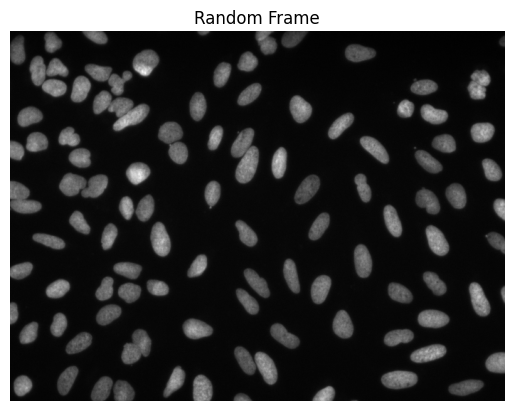

In [9]:
from pathlib import Path
import tifffile as tfi
import matplotlib.pyplot as plt
import random

# Builds a safe path starting from your current directory
search_pattern = str(Path('dataset/raw_images') / '*.tif')

with tfi.TiffSequence(search_pattern) as seq:
    images = seq.asarray()

print(f"Success! Loaded array with shape: {images.shape}")

image_index=random.randint(0, len(images)-1)  # Randomly select an image index (randint upper bound is inclusive)
# images[0] selects the random image in the TIFF sequence
plt.imshow(images[image_index], cmap='gray')
plt.title("Random Frame")
plt.axis('off')
plt.show()

## Data Augmentation

In [10]:
import cv2
import numpy as np
import torch
import albumentations as A
from albumentations.pytorch import ToTensorV2

train_transform=A.Compose([
    #no resize to 512x512 to avoid warping shapes, we will use random crops instead
    A.RandomCrop(512,512),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),

    #these augmentations are simulating real-world cellular physics and microscope hardware flaws.
    A.GaussNoise(p=0.2),
    A.GaussianBlur(blur_limit=(3,7), p=0.2),
    A.ElasticTransform(alpha=120, sigma=12, alpha_affine=120 * 0.03, p=0.2),
    ToTensorV2(),
])




test_transform=A.Compose([
    # Fully-convolutional U-Nets accept any input size, so no crop is needed here.
    # Cropping validation/test images would discard tissue at the borders.
    ToTensorV2(),
])


/tmp/ipykernel_3410/3912008191.py:17: UserWarning: Argument(s) 'alpha_affine' are not valid for transform ElasticTransform
  A.ElasticTransform(alpha=120, sigma=12, alpha_affine=120 * 0.03, p=0.2),


## Percentile Based Normalization

In [11]:
import numpy as np
from pathlib import Path
import tifffile as tfi
import skimage.io as io
from skimage import exposure
import skimage
import torch
from torch.utils.data import Dataset

class NucleusDataset(Dataset):
    def __init__(self, image_dir, annotation_dir, transform=None, indices=None):
        self.image_paths = list(Path(image_dir).glob('*.tif'))
        self.mask_dir = Path(annotation_dir)
        self.transform = transform
        # Optional index filter: lets the seeded train/val/test split be passed in
        if indices is not None:
            self.image_paths = [self.image_paths[i] for i in indices]

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image_path = self.image_paths[idx]
        raw_name = image_path.stem
        mask_path = self.mask_dir / f"{raw_name}.png"

        assert image_path.is_file(), f"Image file {image_path} does not exist"
        assert mask_path.is_file(), f"Mask file {mask_path} missing for image {image_path}"

        # Load the arrays
        image = tfi.imread(image_path)
        mask = io.imread(mask_path)[:, :, 0]  # BBBC039 masks are RGBA; the integer label ID lives in the R channel
        foreground = (mask > 0).astype(np.uint8)
        background = (mask == 0).astype(np.uint8)
        boundary=skimage.segmentation.find_boundaries(mask,mode='inner').astype(np.uint8)
        interior = foreground - boundary
        mask_stacked = np.stack([background, boundary, interior], axis=-1)

        p_low, p_high = np.percentile(image, (1, 99))#Calculate percentiles for THIS image only
        #we use 1st and 99th percentiles to remove dead pixels and hardware noise/outliers. we do this for each image as the lighting conditions and exposure times may vary between images, so we need to normalize each image individually to ensure consistent intensity ranges across the dataset.

        normalized_image = exposure.rescale_intensity(
            image,
            in_range=(p_low, p_high),
            out_range=(0.0, 1.0)#we make the output range 0.0 to 1.0 as this rangeis what the loss function and optimizer gradients are tuned for,having too big values will make the gradients explode and training will fail
        ).astype(np.float32)  # skimage returns float64 here; OpenCV/albumentations require float32


        if self.transform:
            augmented=self.transform(image=normalized_image,mask=mask_stacked)
            #img_tensor=torch.tensor(augmented['image'],dtype=torch.float32)
            #mask_tensor=torch.tensor(augmented['mask'],dtype=torch.float32)
            img_tensor = augmented['image'].detach().clone().type(torch.float32)
            mask_tensor = augmented['mask'].detach().clone().type(torch.float32)
            # albumentations 2.x keeps masks channel-last (H,W,C) -> normalize to (C,H,W)
            if mask_tensor.dim() == 3 and mask_tensor.shape[-1] == 3:
                mask_tensor = mask_tensor.permute(2, 0, 1)
        else:
            # PyTorch expects shape (Channels, Height, Width), so we add a channel dimension using unsqueeze(0)
            img_tensor = torch.tensor(normalized_image, dtype=torch.float32).unsqueeze(0)
            mask_tensor = torch.tensor(mask_stacked, dtype=torch.float32).permute(2, 0, 1)  # (H, W, 3) -> (C, H, W)


        return img_tensor, mask_tensor

In [12]:
import torch
from torch.utils.data import DataLoader

# Build the dataset using the same paths the download cell wrote to
# (works locally AND on Google Colab as long as the download cell ran first)
base_dataset = NucleusDataset(
    image_dir=config_vars['raw_images_dir'],
    annotation_dir=config_vars['raw_annotations_dir'],
)

# 1. SCIENTIFIC REPRODUCIBILITY: Lock the random seed so all 8 models get the exact same split
generator = torch.Generator().manual_seed(42)
indices = torch.randperm(len(base_dataset), generator=generator).tolist()
n_train = int(len(indices) * 0.50)
n_val   = int(len(indices) * 0.25)

# 2. Per-split datasets: training gets augmentation, validation/test stay untouched
train_dataset = NucleusDataset(
    image_dir=config_vars['raw_images_dir'],
    annotation_dir=config_vars['raw_annotations_dir'],
    transform=train_transform,
    indices=indices[:n_train],
)
valid_dataset = NucleusDataset(
    image_dir=config_vars['raw_images_dir'],
    annotation_dir=config_vars['raw_annotations_dir'],
    transform=test_transform,
    indices=indices[n_train:n_train + n_val],
)
test_dataset = NucleusDataset(
    image_dir=config_vars['raw_images_dir'],
    annotation_dir=config_vars['raw_annotations_dir'],
    transform=test_transform,
    indices=indices[n_train + n_val:],
)

# 3. HARDWARE EFFICIENCY:
# batch_size based on your VRAM (4 or 8 is usually the limit for a ResNeXt-101 at 512x512)
BATCH_SIZE = 4

# num_workers=0 is the safest for notebooks (Windows and Colab both dislike forking workers there)
train_dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, pin_memory=True)
valid_dataloader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
test_dataloader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)


# Custom Loss Function

For the loss function we will use a customized combination of binary cross entropy and dice loss as nuclei often occupy a small fraction of the total imaging area, standard pixel-wise accuracy is misleading, we counteract this class imbalance by minimizing the loss function below:

$$L_{Total} = -\frac{1}{N}\sum_{i=1}^{N} \left[y_i \log(p_i) + (1-y_i)\log(1-p_i)\right] + \left(1 - \frac{2 \sum_{i=1}^{N} p_i y_i + \epsilon}{\sum_{i=1}^{N} p_i + \sum_{i=1}^{N} y_i + \epsilon}\right)$$

it is basically BCE+Dice Loss

In [13]:
import torch
import torch.nn.functional as F

def BCE_Dice_loss(logits,target):
    """
    The BCE term penalizes pixel-level classificaiton errors whilst
    the Dice term directly maximizes the spatial overlap between prediciton and ground truth.

    """
    # 1. BCE Loss: applies the Sigmoid internally (raw logits are valid input), preventing NaN explosions
    bce_loss=F.binary_cross_entropy_with_logits(logits,target)

    # 2.Dice Loss (foreground channels only: boundary + interior, so background pixels cannot dominate)
    pred=torch.sigmoid(logits)# Manually apply Sigmoid to get 0.0-1.0 probabilities
    epsilon=1e-6
    intersection = torch.sum(pred[:, 1:] * target[:, 1:])
    union = torch.sum(pred[:, 1:]) + torch.sum(target[:, 1:])
    dice_score=(2.0*intersection+epsilon)/(union+epsilon)
    dice_loss=1.0-dice_score

    return bce_loss+dice_loss



# Models

Do note that you only really need to run one of the models since in the training we just change the backbone name to use a different ResNet but i kept it here to show what models i'm going to use and basically what im going to do to connect it with the decoder

## Decoder

In [14]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class DecoderBlock(nn.Module):
    def __init__(self,in_channels,skip_channels,out_channels):
        super().__init__()
        # Calculate the massive channel dimension after concatenation
        concat_channels=in_channels+skip_channels

        # First convolution compresses the concatenated channels down to the out_channels
        self.conv1=nn.Conv2d(concat_channels,out_channels,kernel_size=3,padding=1,bias=False)
        self.bn1=nn.BatchNorm2d(out_channels)
        self.relu=nn.ReLU(inplace=True)

        # Second convolution refines the fused spatial and semantic features
        self.conv2=nn.Conv2d(out_channels,out_channels,kernel_size=3,padding=1,bias=False)
        self.bn2=nn.BatchNorm2d(out_channels)

    def forward(self,x,skip):
        # 1. Upsample the deeper, lower-resolution feature map
        # We use bilinear interpolation to prevent morphological checkerboard artifacts
        x=F.interpolate(x,size=skip.shape[2:],mode='bilinear',align_corners=False)  # .shape not .size (size is a method)

        # 2. Fuse it with the high-resolution skip connection along the channel axis
        x=torch.cat([x,skip],dim=1)

        # 3. Process through the Double Conv + BatchNorm blocks
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)

        x = self.conv2(x)
        x = self.bn2(x)
        x = self.relu(x)

        return x

In [15]:
import torch.nn.functional as F

class Decoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.decoder1=DecoderBlock(in_channels=2048,skip_channels=1024,out_channels=1024)
        self.decoder2=DecoderBlock(in_channels=1024,skip_channels=512,out_channels=512)
        self.decoder3=DecoderBlock(in_channels=512,skip_channels=256,out_channels=256)
        self.decoder4=DecoderBlock(in_channels=256,skip_channels=64,out_channels=128)
        self.segmentation_head=nn.Conv2d(in_channels=128,out_channels=3,kernel_size=1,padding=0)
    def forward(self,features):
        x=features[4]
        x=self.decoder1(x,features[3])
        x=self.decoder2(x,features[2])
        x=self.decoder3(x,features[1])
        x=self.decoder4(x,features[0])
        x=self.segmentation_head(x)
        # The skip chain ends at 1/2 input resolution; one final 2x upsample brings
        # the logits back to full input resolution (e.g. 256x256 -> 512x512)
        x=F.interpolate(x,scale_factor=2,mode='bilinear',align_corners=False)
        return x


## ResNet 50

In [16]:
import timm
import torch
import torch.nn as nn

class UNet(nn.Module):
    def __init__(self,backbone_name="resnet50"):
        super().__init__()

        #Initialize the encoder (features_only=True severs the classifier and returns the list of 5 tensors)
        self.encoder=timm.create_model(backbone_name,pretrained=True,features_only=True)
        conv1_weights = self.encoder.conv1.weight.clone()
        extracted_weights = torch.sum(conv1_weights, dim=1, keepdim=True)

        # Extract and swap the stem for 1-channel grayscale input
        new_conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=conv1_weights.shape[0],
            kernel_size=conv1_weights.shape[2:],
            stride=self.encoder.conv1.stride,
            padding=self.encoder.conv1.padding,
            bias=False # ResNet stems don't use bias because BatchNorm follows immediately
            )
        new_conv1.weight = nn.Parameter(extracted_weights)
        self.encoder.conv1 = new_conv1
        self.decoder=Decoder()

    def forward(self,x):
        features=self.encoder(x)
        output=self.decoder(features)
        return output





## ResNet 101

In [17]:
import timm
import torch
import torch.nn as nn

class UNet(nn.Module):
    def __init__(self,backbone_name="resnet101"):
        super().__init__()

        #Initialize the encoder (features_only=True severs the classifier and returns the list of 5 tensors)
        self.encoder=timm.create_model(backbone_name,pretrained=True,features_only=True)
        conv1_weights = self.encoder.conv1.weight.clone()
        extracted_weights = torch.sum(conv1_weights, dim=1, keepdim=True)

        # Extract and swap the stem for 1-channel grayscale input
        new_conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=conv1_weights.shape[0],
            kernel_size=conv1_weights.shape[2:],
            stride=self.encoder.conv1.stride,
            padding=self.encoder.conv1.padding,
            bias=False # ResNet stems don't use bias because BatchNorm follows immediately
            )
        new_conv1.weight = nn.Parameter(extracted_weights)
        self.encoder.conv1 = new_conv1
        self.decoder=Decoder()

    def forward(self,x):
        features=self.encoder(x)
        output=self.decoder(features)
        return output





## Wide-ResNet 50


In [18]:
import timm
import torch
import torch.nn as nn

class UNet(nn.Module):
    def __init__(self,backbone_name="wide_resnet50_2"):
        super().__init__()

        #Initialize the encoder (features_only=True severs the classifier and returns the list of 5 tensors)
        self.encoder=timm.create_model(backbone_name,pretrained=True,features_only=True)
        conv1_weights = self.encoder.conv1.weight.clone()
        extracted_weights = torch.sum(conv1_weights, dim=1, keepdim=True)

        # Extract and swap the stem for 1-channel grayscale input
        new_conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=conv1_weights.shape[0],
            kernel_size=conv1_weights.shape[2:],
            stride=self.encoder.conv1.stride,
            padding=self.encoder.conv1.padding,
            bias=False # ResNet stems don't use bias because BatchNorm follows immediately
            )
        new_conv1.weight = nn.Parameter(extracted_weights)
        self.encoder.conv1 = new_conv1
        self.decoder=Decoder()

    def forward(self,x):
        features=self.encoder(x)
        output=self.decoder(features)
        return output





## Wide-ResNet 101

In [19]:
import timm
import torch
import torch.nn as nn

class UNet(nn.Module):
    def __init__(self,backbone_name="wide_resnet101_2"):
        super().__init__()

        #Initialize the encoder (features_only=True severs the classifier and returns the list of 5 tensors)
        self.encoder=timm.create_model(backbone_name,pretrained=True,features_only=True)
        conv1_weights = self.encoder.conv1.weight.clone()
        extracted_weights = torch.sum(conv1_weights, dim=1, keepdim=True)

        # Extract and swap the stem for 1-channel grayscale input
        new_conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=conv1_weights.shape[0],
            kernel_size=conv1_weights.shape[2:],
            stride=self.encoder.conv1.stride,
            padding=self.encoder.conv1.padding,
            bias=False # ResNet stems don't use bias because BatchNorm follows immediately
            )
        new_conv1.weight = nn.Parameter(extracted_weights)
        self.encoder.conv1 = new_conv1
        self.decoder=Decoder()

    def forward(self,x):
        features=self.encoder(x)
        output=self.decoder(features)
        return output





## ResNext 50

In [20]:
import timm
import torch
import torch.nn as nn

class UNet(nn.Module):
    def __init__(self,backbone_name="resnext50_32x4d"):
        super().__init__()

        #Initialize the encoder (features_only=True severs the classifier and returns the list of 5 tensors)
        self.encoder=timm.create_model(backbone_name,pretrained=True,features_only=True)
        conv1_weights = self.encoder.conv1.weight.clone()
        extracted_weights = torch.sum(conv1_weights, dim=1, keepdim=True)

        # Extract and swap the stem for 1-channel grayscale input
        new_conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=conv1_weights.shape[0],
            kernel_size=conv1_weights.shape[2:],
            stride=self.encoder.conv1.stride,
            padding=self.encoder.conv1.padding,
            bias=False # ResNet stems don't use bias because BatchNorm follows immediately
            )
        new_conv1.weight = nn.Parameter(extracted_weights)
        self.encoder.conv1 = new_conv1
        self.decoder=Decoder()

    def forward(self,x):
        features=self.encoder(x)
        output=self.decoder(features)
        return output





## ResNext 101

In [21]:
import timm
import torch
import torch.nn as nn

class UNet(nn.Module):
    def __init__(self,backbone_name="resnext101_64x4d"):
        super().__init__()

        #Initialize the encoder (features_only=True severs the classifier and returns the list of 5 tensors)
        self.encoder=timm.create_model(backbone_name,pretrained=True,features_only=True)
        conv1_weights = self.encoder.conv1.weight.clone()
        extracted_weights = torch.sum(conv1_weights, dim=1, keepdim=True)

        # Extract and swap the stem for 1-channel grayscale input
        new_conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=conv1_weights.shape[0],
            kernel_size=conv1_weights.shape[2:],
            stride=self.encoder.conv1.stride,
            padding=self.encoder.conv1.padding,
            bias=False # ResNet stems don't use bias because BatchNorm follows immediately
            )
        new_conv1.weight = nn.Parameter(extracted_weights)
        self.encoder.conv1 = new_conv1
        self.decoder=Decoder()

    def forward(self,x):
        features=self.encoder(x)
        output=self.decoder(features)
        return output





## SEResNext 50

In [22]:
import timm
import torch
import torch.nn as nn

class UNet(nn.Module):
    def __init__(self,backbone_name="seresnext50_32x4d"):
        super().__init__()

        #Initialize the encoder (features_only=True severs the classifier and returns the list of 5 tensors)
        self.encoder=timm.create_model(backbone_name,pretrained=True,features_only=True)
        conv1_weights = self.encoder.conv1.weight.clone()
        extracted_weights = torch.sum(conv1_weights, dim=1, keepdim=True)

        # Extract and swap the stem for 1-channel grayscale input
        new_conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=conv1_weights.shape[0],
            kernel_size=conv1_weights.shape[2:],
            stride=self.encoder.conv1.stride,
            padding=self.encoder.conv1.padding,
            bias=False # ResNet stems don't use bias because BatchNorm follows immediately
            )
        new_conv1.weight = nn.Parameter(extracted_weights)
        self.encoder.conv1 = new_conv1
        self.decoder=Decoder()

    def forward(self,x):
        features=self.encoder(x)
        output=self.decoder(features)
        return output





## SEResNext 101

In [23]:
import timm
import torch
import torch.nn as nn

class UNet(nn.Module):
    def __init__(self,backbone_name="seresnext101_32x8d"):
        super().__init__()

        #Initialize the encoder (features_only=True severs the classifier and returns the list of 5 tensors)
        self.encoder=timm.create_model(backbone_name,pretrained=True,features_only=True)
        conv1_weights = self.encoder.conv1.weight.clone()
        extracted_weights = torch.sum(conv1_weights, dim=1, keepdim=True)

        # Extract and swap the stem for 1-channel grayscale input
        new_conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=conv1_weights.shape[0],
            kernel_size=conv1_weights.shape[2:],
            stride=self.encoder.conv1.stride,
            padding=self.encoder.conv1.padding,
            bias=False # ResNet stems don't use bias because BatchNorm follows immediately
            )
        new_conv1.weight = nn.Parameter(extracted_weights)
        self.encoder.conv1 = new_conv1
        self.decoder=Decoder()

    def forward(self,x):
        features=self.encoder(x)
        output=self.decoder(features)
        return output





# Training

## ResNet50

In [24]:
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau

resnet50=UNet(backbone_name="resnet50")
resnet50=resnet50.cuda()

ENCODER_LR=1e-4
DECODER_LR=1e-3

resnet50_optimizer=optim.AdamW([
    {"params":resnet50.encoder.parameters(),"lr":ENCODER_LR},# Very low: gently fine-tunes the edge-detection weights for microscopy
    {"params":resnet50.decoder.parameters(),"lr":DECODER_LR},# High: aggressively trains the untrained spatial routing blocks
],weight_decay=1e-4)

resnet50_scheduler = ReduceLROnPlateau(
    resnet50_optimizer,
    mode='min',      # We want the validation loss to minimize
    factor=0.1,      # Multiply both LRs by 0.1 (drop by 10x) when triggered
    patience=3,      # Wait for 3 epochs of no improvement before dropping
   # verbose=True     # Prints a console message when the LR drops
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

## ResNet101

In [25]:
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau

resnet101=UNet(backbone_name="resnet101")
resnet101=resnet101.cuda()

ENCODER_LR=1e-4
DECODER_LR=1e-3

resnet101_optimizer=optim.AdamW([
    {"params":resnet101.encoder.parameters(),"lr":ENCODER_LR},# Very low: gently fine-tunes the edge-detection weights for microscopy
    {"params":resnet101.decoder.parameters(),"lr":DECODER_LR},# High: aggressively trains the untrained spatial routing blocks
],weight_decay=1e-4)

resnet101_scheduler = ReduceLROnPlateau(
    resnet101_optimizer,
    mode='min',      # We want the validation loss to minimize
    factor=0.1,      # Multiply both LRs by 0.1 (drop by 10x) when triggered
    patience=3,      # Wait for 3 epochs of no improvement before dropping
    #verbose=True     # Prints a console message when the LR drops
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  179MB            

model.safetensors: downloading bytes:           |  0.00B            

## Wide-Resnet 50

In [26]:
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau

wide_resnet50=UNet(backbone_name="wide_resnet50_2")
wide_resnet50=wide_resnet50.cuda()

ENCODER_LR=1e-4
DECODER_LR=1e-3

wide_resnet50_optimizer=optim.AdamW([
    {"params":wide_resnet50.encoder.parameters(),"lr":ENCODER_LR},# Very low: gently fine-tunes the edge-detection weights for microscopy
    {"params":wide_resnet50.decoder.parameters(),"lr":DECODER_LR},# High: aggressively trains the untrained spatial routing blocks
],weight_decay=1e-4)

wide_resnet50_scheduler = ReduceLROnPlateau(
    wide_resnet50_optimizer,
    mode='min',      # We want the validation loss to minimize
    factor=0.1,      # Multiply both LRs by 0.1 (drop by 10x) when triggered
    patience=3,      # Wait for 3 epochs of no improvement before dropping
    #verbose=True     # Prints a console message when the LR drops
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  276MB            

model.safetensors: downloading bytes:           |  0.00B            

## Wide-Resnet 101

In [27]:
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau

wide_resnet101=UNet(backbone_name="wide_resnet101_2")
wide_resnet101=wide_resnet101.cuda()

ENCODER_LR=1e-4
DECODER_LR=1e-3

wide_resnet101_optimizer=optim.AdamW([
    {"params":wide_resnet101.encoder.parameters(),"lr":ENCODER_LR},# Very low: gently fine-tunes the edge-detection weights for microscopy
    {"params":wide_resnet101.decoder.parameters(),"lr":DECODER_LR},# High: aggressively trains the untrained spatial routing blocks
],weight_decay=1e-4)

wide_resnet101_scheduler = ReduceLROnPlateau(
    wide_resnet101_optimizer,
    mode='min',      # We want the validation loss to minimize
    factor=0.1,      # Multiply both LRs by 0.1 (drop by 10x) when triggered
    patience=3,      # Wait for 3 epochs of no improvement before dropping
   # verbose=True     # Prints a console message when the LR drops
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  508MB            

model.safetensors: downloading bytes:           |  0.00B            

## ResNext 50

In [28]:
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau

res_next50=UNet(backbone_name="resnext50_32x4d")
res_next50=res_next50.cuda()

ENCODER_LR=1e-4
DECODER_LR=1e-3

res_next50_optimizer=optim.AdamW([
    {"params":res_next50.encoder.parameters(),"lr":ENCODER_LR},# Very low: gently fine-tunes the edge-detection weights for microscopy
    {"params":res_next50.decoder.parameters(),"lr":DECODER_LR},# High: aggressively trains the untrained spatial routing blocks
],weight_decay=1e-4)

res_next50_scheduler = ReduceLROnPlateau(
    res_next50_optimizer,
    mode='min',      # We want the validation loss to minimize
    factor=0.1,      # Multiply both LRs by 0.1 (drop by 10x) when triggered
    patience=3,      # Wait for 3 epochs of no improvement before dropping
   # verbose=True     # Prints a console message when the LR drops
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  100MB            

model.safetensors: downloading bytes:           |  0.00B            

## ResNext 101

In [29]:
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau

res_next101=UNet(backbone_name="resnext101_64x4d")
res_next101=res_next101.cuda()

ENCODER_LR=1e-4
DECODER_LR=1e-3

res_next101_optimizer=optim.AdamW([
    {"params":res_next101.encoder.parameters(),"lr":ENCODER_LR},# Very low: gently fine-tunes the edge-detection weights for microscopy
    {"params":res_next101.decoder.parameters(),"lr":DECODER_LR},# High: aggressively trains the untrained spatial routing blocks
],weight_decay=1e-4)

res_next101_scheduler = ReduceLROnPlateau(
    res_next101_optimizer,
    mode='min',      # We want the validation loss to minimize
    factor=0.1,      # Multiply both LRs by 0.1 (drop by 10x) when triggered
    patience=3,      # Wait for 3 epochs of no improvement before dropping
    #verbose=True     # Prints a console message when the LR drops
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

model.safetensors: downloading bytes:           |  0.00B            

## SEResNext 50

In [30]:
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau

se_res_next50=UNet(backbone_name="seresnext50_32x4d")

ENCODER_LR=1e-4
DECODER_LR=1e-3

se_res_next50_optimizer=optim.AdamW([
    {"params":se_res_next50.encoder.parameters(),"lr":ENCODER_LR},# Very low: gently fine-tunes the edge-detection weights for microscopy
    {"params":se_res_next50.decoder.parameters(),"lr":DECODER_LR},# High: aggressively trains the untrained spatial routing blocks
],weight_decay=1e-4)

se_res_next50_scheduler = ReduceLROnPlateau(
    se_res_next50_optimizer,
    mode='min',      # We want the validation loss to minimize
    factor=0.1,      # Multiply both LRs by 0.1 (drop by 10x) when triggered
    patience=3,      # Wait for 3 epochs of no improvement before dropping
    #verbose=True     # Prints a console message when the LR drops
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  111MB            

model.safetensors: downloading bytes:           |  0.00B            

## SEResNext 101

In [31]:
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau

se_res_next101=UNet(backbone_name="seresnext101_32x8d")

ENCODER_LR=1e-4
DECODER_LR=1e-3

se_res_next101_optimizer=optim.AdamW([
    {"params":se_res_next101.encoder.parameters(),"lr":ENCODER_LR},# Very low: gently fine-tunes the edge-detection weights for microscopy
    {"params":se_res_next101.decoder.parameters(),"lr":DECODER_LR},# High: aggressively trains the untrained spatial routing blocks
],weight_decay=1e-4)

se_res_next101_scheduler = ReduceLROnPlateau(
    se_res_next101_optimizer,
    mode='min',      # We want the validation loss to minimize
    factor=0.1,      # Multiply both LRs by 0.1 (drop by 10x) when triggered
    patience=3,      # Wait for 3 epochs of no improvement before dropping
    #verbose=True     # Prints a console message when the LR drops
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  375MB            

model.safetensors: downloading bytes:           |  0.00B            

In [32]:

NUM_EPOCHS=100

In [33]:
models=[resnet50,resnet101,wide_resnet50,wide_resnet101,res_next50,res_next101,se_res_next50,se_res_next101]  # all 8 backbones
optimizers=[resnet50_optimizer,resnet101_optimizer,wide_resnet50_optimizer,wide_resnet101_optimizer,res_next50_optimizer,res_next101_optimizer,se_res_next50_optimizer,se_res_next101_optimizer]
schedulers=[resnet50_scheduler,resnet101_scheduler,wide_resnet50_scheduler,wide_resnet101_scheduler,res_next50_scheduler,res_next101_scheduler,se_res_next50_scheduler,se_res_next101_scheduler]
# You need a list of names to properly save the files
backbone_names = ["resnet50", "resnet101", "wide_resnet50", "wide_resnet101",
                  "resnext50", "resnext101", "seresnext50", "seresnext101"]

## Option B: Use the finished models (skip training)

Already trained everything (or some of the backbones) and just want to
evaluate or interpret the results?

1. Run everything up to the model lists cell as usual (download + dataset +
   model definitions + instantiation — **no training happens**).
2. Run the loader cell right below **instead of** the training cell. It lists
   every file in the checkpoint folder (your Google Drive folder on Colab),
   shows the training status of each backbone, and loads every finished
   `<name>_best.pth` into its model.
3. You can then run the evaluation cells and the interpretability cells
   directly — they only use the models that were actually found on Drive.


In [34]:
import os
import json
import torch

# ================= LOAD FINISHED MODELS (SKIP TRAINING) =================
# Alternative to the training cell: lists the checkpoint folder (Google
# Drive on Colab), shows the training status of every backbone, and loads
# each finished <name>_best.pth so the evaluation + interpretability cells
# can run without any training.

if 'CHECKPOINT_DIR' not in globals():
    CHECKPOINT_DIR = '/content/drive/MyDrive/bbbc039_checkpoints' if os.path.exists('/content/drive/MyDrive') else 'checkpoints'
PROGRESS_FILE = os.path.join(CHECKPOINT_DIR, 'training_progress.json')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Checkpoint folder: {CHECKPOINT_DIR}")

# --- 1. What is in the checkpoint folder? ---
print("\nFiles found:")
if os.path.isdir(CHECKPOINT_DIR):
    files = sorted(os.listdir(CHECKPOINT_DIR))
    if not files:
        print("  (folder is empty - nothing has been trained yet)")
    for fname in files:
        size_mb = os.path.getsize(os.path.join(CHECKPOINT_DIR, fname)) / (1024 ** 2)
        print(f"  {fname:<40s} {size_mb:9.2f} MB")
else:
    print(f"  (folder not found - did you mount Drive and train at least once?)")

# --- 2. Training status from the manifest ---
progress = {}
if os.path.exists(PROGRESS_FILE):
    with open(PROGRESS_FILE) as f:
        progress = json.load(f)
    print("\nTraining status (training_progress.json):")
    for name in backbone_names:
        info = progress.get(name, {})
        status = info.get('status', 'pending')
        detail = f"epoch {info.get('last_epoch', '-')}"
        if info.get('best_val_loss') is not None:
            detail += f", best val loss {info['best_val_loss']:.4f}"
        if info.get('early_stopped'):
            detail += ", early-stopped"
        print(f"  {name:<20s} {status:<10s} {detail}")
else:
    print("\nNo training_progress.json found (nothing trained yet?).")

# --- 3. Load every finished model ---
print("\nLoading finished models:")
loaded = 0
for idx, model in enumerate(models):
    name = backbone_names[idx]
    best_path = os.path.join(CHECKPOINT_DIR, f"{name}_best.pth")

    if os.path.exists(best_path):
        model.load_state_dict(torch.load(best_path, map_location='cpu'))
        model.to(device)
        model.eval()
        loaded += 1
        print(f"  [LOADED]  {name}")
    else:
        print(f"  [SKIPPED] {name} - no {name}_best.pth found yet")

print(f"\n{loaded}/{len(backbone_names)} models ready. You can now run:")
print("  * the biological/hardware benchmark cell -> uses every loaded model")
print("  * the prediction grid cell             -> plots every loaded model")
print("  * the interpretability cells           -> e.g. Segmentation_Grad_CAM(resnet50, sample_image)")


Checkpoint folder: /content/drive/MyDrive/bbbc039_checkpoints

Files found:
  resnet101_best.pth                          353.76 MB
  resnet101_checkpoint.pth                   1060.26 MB
  resnet101_loss_curves.json                    0.00 MB
  resnet50_best.pth                           281.01 MB
  resnet50_checkpoint.pth                     842.47 MB
  resnet50_loss_curves.json                     0.00 MB
  resnext101_best.pth                         502.55 MB
  resnext101_checkpoint.pth                  1505.87 MB
  resnext101_loss_curves.json                   0.00 MB
  resnext50_best.pth                          279.05 MB
  resnext50_checkpoint.pth                    836.49 MB
  resnext50_loss_curves.json                    0.00 MB
  seresnext101_best.pth                       541.18 MB
  seresnext101_checkpoint.pth                1621.79 MB
  seresnext101_loss_curves.json                 0.00 MB
  seresnext50_best.pth                        288.73 MB
  seresnext50_checkpoint.pth

# MODEL TRAINING

In [ ]:
import os
import json
import time
import shutil
import torch

# ================= CHECKPOINTING SETUP =================
# Everything (best weights, resumable checkpoints, progress manifest, loss curves)
# lives in CHECKPOINT_DIR. On Colab this auto-resolves to a Google Drive folder
# when Drive is mounted, so the experiment survives runtime disconnects.
if 'CHECKPOINT_DIR' not in globals():
    CHECKPOINT_DIR = '/content/drive/MyDrive/bbbc039_checkpoints' if os.path.exists('/content/drive/MyDrive') else 'checkpoints'
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# Fast in-session storage: the full checkpoint is written here EVERY epoch and
# synced to CHECKPOINT_DIR (Drive) every CKPT_SYNC_EVERY epochs, so a Colab
# disconnect costs at most CKPT_SYNC_EVERY epochs of progress.
if 'LOCAL_CKPT_DIR' not in globals():
    LOCAL_CKPT_DIR = 'checkpoints_local'
os.makedirs(LOCAL_CKPT_DIR, exist_ok=True)

PROGRESS_FILE = os.path.join(CHECKPOINT_DIR, 'training_progress.json')
CKPT_SYNC_EVERY = 5          # epochs between local -> persistent checkpoint syncs
EARLY_STOPPING_PATIENCE = 10 # stop a model after this many epochs without val-loss improvement

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Checkpoints: persistent -> {CHECKPOINT_DIR} | in-session -> {LOCAL_CKPT_DIR}")

def local_ckpt_path(name):
    return os.path.join(LOCAL_CKPT_DIR, f"{name}_checkpoint.pth")

def persistent_ckpt_path(name):
    return os.path.join(CHECKPOINT_DIR, f"{name}_checkpoint.pth")

def best_weights_path(name):
    return os.path.join(CHECKPOINT_DIR, f"{name}_best.pth")

def load_progress():
    """Manifest {model_name: {...}} tracking which models are done / resumable."""
    if os.path.exists(PROGRESS_FILE):
        with open(PROGRESS_FILE) as f:
            return json.load(f)
    return {}

def save_progress(progress):
    with open(PROGRESS_FILE, 'w') as f:
        json.dump(progress, f, indent=2)

def sync_all(name):
    """Copy the in-session checkpoint + best weights to the persistent folder."""
    shutil.copyfile(local_ckpt_path(name), persistent_ckpt_path(name))
    local_best = os.path.join(LOCAL_CKPT_DIR, f"{name}_best.pth")
    if os.path.exists(local_best):
        shutil.copyfile(local_best, best_weights_path(name))

def save_checkpoint(name, model, optimizer, scheduler, epoch, best_val_loss, loss_history, early_stopped):
    """Full resumable state: weights + optimizer + scheduler + epoch + loss history."""
    torch.save({
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'best_val_loss': best_val_loss,
        'loss_history': loss_history,
        'early_stopped': early_stopped,
    }, local_ckpt_path(name))
    if (epoch + 1) % CKPT_SYNC_EVERY == 0:
        sync_all(name)

models=[resnet50,resnet101,wide_resnet50,wide_resnet101,res_next50,res_next101,se_res_next50,se_res_next101]  # all 8 backbones
optimizers=[resnet50_optimizer,resnet101_optimizer,wide_resnet50_optimizer,wide_resnet101_optimizer,res_next50_optimizer,res_next101_optimizer,se_res_next50_optimizer,se_res_next101_optimizer]
schedulers=[resnet50_scheduler,resnet101_scheduler,wide_resnet50_scheduler,wide_resnet101_scheduler,res_next50_scheduler,res_next101_scheduler,se_res_next50_scheduler,se_res_next101_scheduler]
# You need a list of names to properly save the files
backbone_names = ["resnet50", "resnet101", "wide_resnet50", "wide_resnet101",
                  "resnext50", "resnext101", "seresnext50", "seresnext101"]

progress = load_progress()

# --- Status overview: what is done, what can resume ---
print("\nTraining status (from " + PROGRESS_FILE + "):")
for name in backbone_names:
    info = progress.get(name, {})
    print(f"  {name}: {info.get('status', 'pending')}")

for idx in range(len(models)):
    name = backbone_names[idx]
    print(f"\n========== TRAINING: {name} ==========")

    # --- SKIP / RESUME logic (re-running this cell is safe and idempotent) ---
    if progress.get(name, {}).get('status') == 'done':
        print(f"Already 'done' - skipping. Delete its manifest entry to retrain it.")
        continue

    start_epoch = 0
    best_val_loss = float('inf')
    loss_history = {"train": [], "val": []}
    early_stopped = False

    # Prefer the in-session checkpoint (freshest); fall back to the persistent
    # one (survives Colab restarts).
    resume_from = None
    for candidate in (local_ckpt_path(name), persistent_ckpt_path(name)):
        if os.path.exists(candidate):
            resume_from = candidate
            break

    if resume_from is not None:
        ckpt = torch.load(resume_from, map_location='cpu')
        models[idx].load_state_dict(ckpt['model_state_dict'])
        models[idx] = models[idx].to(device)
        optimizers[idx].load_state_dict(ckpt['optimizer_state_dict'])
        schedulers[idx].load_state_dict(ckpt['scheduler_state_dict'])
        start_epoch = ckpt['epoch'] + 1
        best_val_loss = ckpt['best_val_loss']
        loss_history = ckpt['loss_history']
        print(f"Resuming {name} from epoch {start_epoch}/{NUM_EPOCHS} (best val loss so far: {best_val_loss:.4f})")
    else:
        models[idx] = models[idx].to(device)
        print(f"No checkpoint found - training {name} from scratch.")

    progress[name] = {'status': 'resuming' if resume_from is not None else 'training',
                      'last_epoch': start_epoch - 1,
                      'best_val_loss': None if resume_from is None else best_val_loss}
    save_progress(progress)

    # Reset GPU memory stats for accurate VRAM tracking (GPU only)
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    start_time = time.time()
    stale_epochs = 0  # consecutive epochs without val-loss improvement (early stopping)
    last_epoch = start_epoch - 1

    for epoch in range(start_epoch, NUM_EPOCHS):
        last_epoch = epoch

        # --- TRAIN ---
        models[idx].train()
        epoch_train_loss = 0.0

        for images, masks in train_dataloader:
            images, masks = images.to(device), masks.to(device)

            optimizers[idx].zero_grad()
            pred = models[idx](images)
            loss = BCE_Dice_loss(pred, masks) # Use your actual loss function name
            loss.backward()
            optimizers[idx].step()

            epoch_train_loss += loss.item()

        epoch_train_loss /= len(train_dataloader)
        loss_history["train"].append(epoch_train_loss)

        # --- VALIDATION ---
        models[idx].eval()
        epoch_val_loss = 0.0

        with torch.no_grad():
            for images, masks in valid_dataloader:
                images, masks = images.to(device), masks.to(device)
                pred = models[idx](images)
                loss = BCE_Dice_loss(pred, masks)
                epoch_val_loss += loss.item()

        epoch_val_loss /= len(valid_dataloader)
        loss_history["val"].append(epoch_val_loss)

        # --- BEST-WEIGHTS CHECKPOINT (what the evaluation cells load) ---
        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            # Save to the in-session folder first (fast); sync_all() pushes it to Drive
            torch.save(models[idx].state_dict(), os.path.join(LOCAL_CKPT_DIR, f"{name}_best.pth"))
            print(f"Epoch {epoch+1}: New best model saved! (Loss: {best_val_loss:.4f})")
            stale_epochs = 0
        else:
            stale_epochs += 1

        # Step the scheduler
        schedulers[idx].step(epoch_val_loss)
        print(f"Epoch {epoch+1} | Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f}")

        # --- EARLY STOPPING ---
        if stale_epochs >= EARLY_STOPPING_PATIENCE:
            print(f"Early stopping triggered: {EARLY_STOPPING_PATIENCE} epochs without val-loss improvement.")
            early_stopped = True
            save_checkpoint(name, models[idx], optimizers[idx], schedulers[idx], epoch, best_val_loss, loss_history, early_stopped)
            sync_all(name)
            break

        # --- FULL RESUME CHECKPOINT (every epoch) ---
        save_checkpoint(name, models[idx], optimizers[idx], schedulers[idx], epoch, best_val_loss, loss_history, early_stopped)

    # --- POST-TRAINING: final sync to the persistent folder + metrics ---
    if os.path.exists(local_ckpt_path(name)):
        sync_all(name)

    total_time = time.time() - start_time
    # Convert bytes to Megabytes (0 on CPU-only machines)
    peak_vram = torch.cuda.max_memory_allocated() / (1024 ** 2) if torch.cuda.is_available() else 0.0

    print(f"\n--- {name} Completed ---")
    print(f"Total Time: {total_time/60:.2f} minutes")
    print(f"Peak VRAM: {peak_vram:.2f} MB")

    # Save the loss curves to a JSON file so you can graph them later
    with open(os.path.join(CHECKPOINT_DIR, f"{name}_loss_curves.json"), "w") as f:
        json.dump(loss_history, f)

    progress[name] = {'status': 'done',
                      'last_epoch': last_epoch,
                      'best_val_loss': best_val_loss,
                      'early_stopped': early_stopped,
                      'time_minutes': round(total_time / 60, 2),
                      'peak_vram_mb': round(peak_vram, 2)}
    save_progress(progress)

print("\n========== TRAINING PIPELINE FINISHED ==========")
for name in backbone_names:
    info = progress.get(name, {})
    print(f"  {name}: {info.get('status', 'unknown')}")


Checkpoints: persistent -> /content/drive/MyDrive/bbbc039_checkpoints | in-session -> checkpoints_local

Training status (from /content/drive/MyDrive/bbbc039_checkpoints/training_progress.json):
  resnet50: done
  resnet101: done
  wide_resnet50: done
  wide_resnet101: done
  resnext50: training
  resnext101: pending
  seresnext50: pending
  seresnext101: pending

========== TRAINING: resnet50 ==========
Already 'done' - skipping. Delete its manifest entry to retrain it.

========== TRAINING: resnet101 ==========
Already 'done' - skipping. Delete its manifest entry to retrain it.

========== TRAINING: wide_resnet50 ==========
Already 'done' - skipping. Delete its manifest entry to retrain it.

========== TRAINING: wide_resnet101 ==========
Already 'done' - skipping. Delete its manifest entry to retrain it.

========== TRAINING: resnext50 ==========
Resuming resnext50 from epoch 60/100 (best val loss so far: 0.1339)
Epoch 61 | Train Loss: 0.1468 | Val Loss: 0.1346
Epoch 62 | Train Loss:

# BENCHMARKING

In [35]:
import os
import torch
import time
import numpy as np
from skimage.measure import label, regionprops
from scipy.stats import ks_2samp

print("\n================ FINAL BIOLOGICAL & HARDWARE BENCHMARK ================")

# Load checkpoints from the same folder training saved to (Drive-backed on Colab)
if 'CHECKPOINT_DIR' not in globals():
    CHECKPOINT_DIR = '/content/drive/MyDrive/bbbc039_checkpoints' if os.path.exists('/content/drive/MyDrive') else 'checkpoints'

for idx in range(len(models)):
    name = backbone_names[idx]
    print(f"\n--- Evaluating {name} ---")

    # 1. Load the exact mathematical state where this model performed best
    best_path = os.path.join(CHECKPOINT_DIR, f"{name}_best.pth")
    if not os.path.exists(best_path):
        print(f"  [SKIP] {name}_best.pth not found - this model has not finished training.")
        continue
    models[idx].load_state_dict(torch.load(best_path, map_location='cpu'))
    models[idx].eval()

    torch.cuda.reset_peak_memory_stats()
    start_time = time.time()

    # 2. Biological Trackers for the entire test set
    total_pred_count = 0
    total_gt_count = 0
    all_pred_areas = []
    all_pred_eccentricities = []
    all_gt_areas = []
    all_gt_eccentricities = []
    forward_time = 0.0   # pure forward-pass time, separate from CPU postprocessing
    n_images = 0

    with torch.no_grad():
        for images, masks in test_dataloader:
            images = images.cuda()
            if torch.cuda.is_available():
                torch.cuda.synchronize()  # start the clock with an idle GPU
            t0 = time.time()
            preds = models[idx](images)
            if torch.cuda.is_available():
                torch.cuda.synchronize()  # wait for the GPU to actually finish
            forward_time += time.time() - t0
            n_images += images.size(0)

            # Convert raw logits to probabilities and move to CPU for scikit-image
            probs = torch.softmax(preds, dim=1).cpu().numpy()
            masks_np = masks.cpu().numpy() # Assuming GT masks are (Batch, 3, H, W)

            # 3. Iterate through each individual image in the batch
            for b in range(images.size(0)):

                # --- PREDICTIONS ---
                boundary_prob = probs[b, 1, :, :]
                interior_prob = probs[b, 2, :, :]

                pred_cores = (interior_prob > 0.5) & ~(boundary_prob > 0.5)
                pred_labeled, _ = label(pred_cores, return_num=True)

                # Filter out single-pixel noise speckles before counting cells
                MIN_NUCLEUS_AREA = 25
                pred_props = [p for p in regionprops(pred_labeled) if p.area >= MIN_NUCLEUS_AREA]
                total_pred_count += len(pred_props)


                all_pred_areas.extend([cell.area for cell in pred_props])
                all_pred_eccentricities.extend([cell.eccentricity for cell in pred_props])

                # --- GROUND TRUTH ---
                gt_boundary = masks_np[b, 1, :, :] > 0.5
                gt_interior = masks_np[b, 2, :, :] > 0.5

                gt_cores = gt_interior & ~gt_boundary
                gt_labeled, gt_count = label(gt_cores, return_num=True)
                total_gt_count += gt_count

                gt_props = regionprops(gt_labeled)
                all_gt_areas.extend([cell.area for cell in gt_props])
                all_gt_eccentricities.extend([cell.eccentricity for cell in gt_props])

    # 4. Hardware Metrics
    total_time = time.time() - start_time
    peak_vram = torch.cuda.max_memory_allocated() / (1024 ** 2)
    avg_pred_ms = (forward_time / n_images * 1000) if n_images else 0.0

    # 5. Biological Metrics (with safety check in case a model fails to predict any cells)
    count_error = abs(total_pred_count - total_gt_count)

    if len(all_pred_areas) > 0 and len(all_gt_areas) > 0:
        area_ks_stat, _ = ks_2samp(all_pred_areas, all_gt_areas)
        ecc_ks_stat, _ = ks_2samp(all_pred_eccentricities, all_gt_eccentricities)
    else:
        area_ks_stat, ecc_ks_stat = float('inf'), float('inf')

    # 6. Output the Final Benchmark Results
    print(f"Total Inference Time: {total_time:.2f} seconds")
    print(f"Avg Prediction Time: {avg_pred_ms:.2f} ms/image")
    print(f"Peak Inference VRAM: {peak_vram:.2f} MB")
    print(f"Predicted Nuclei: {total_pred_count} | Ground Truth: {total_gt_count} | Error: {count_error}")
    print(f"Area Variance (KS-Stat): {area_ks_stat:.4f} (Lower is better)")
    print(f"Eccentricity Variance (KS-Stat): {ecc_ks_stat:.4f} (Lower is better)")


================ FINAL BIOLOGICAL & HARDWARE BENCHMARK ================

--- Evaluating resnet50 ---
Total Inference Time: 7.46 seconds
Avg Prediction Time: 52.63 ms/image
Peak Inference VRAM: 4824.40 MB
Predicted Nuclei: 5268 | Ground Truth: 6162 | Error: 894
Area Variance (KS-Stat): 0.1068 (Lower is better)
Eccentricity Variance (KS-Stat): 0.0401 (Lower is better)

--- Evaluating resnet101 ---
Total Inference Time: 5.03 seconds
Avg Prediction Time: 13.04 ms/image
Peak Inference VRAM: 4823.96 MB
Predicted Nuclei: 5186 | Ground Truth: 6162 | Error: 976
Area Variance (KS-Stat): 0.1209 (Lower is better)
Eccentricity Variance (KS-Stat): 0.0479 (Lower is better)

--- Evaluating wide_resnet50 ---
Total Inference Time: 5.11 seconds
Avg Prediction Time: 13.88 ms/image
Peak Inference VRAM: 4823.96 MB
Predicted Nuclei: 5309 | Ground Truth: 6162 | Error: 853
Area Variance (KS-Stat): 0.0951 (Lower is better)
Eccentricity Variance (KS-Stat): 0.0378 (Lower is better)

--- Evaluating wide_resnet101

Predictions for 8 finished model(s): ['resnet50', 'resnet101', 'wide_resnet50', 'wide_resnet101', 'resnext50', 'resnext101', 'seresnext50', 'seresnext101']


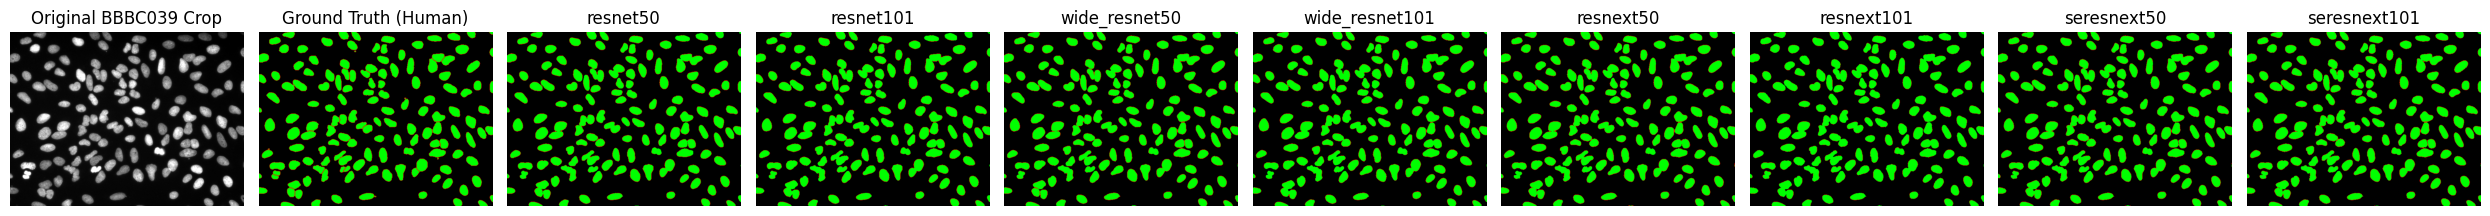

In [36]:
import os
import torch
import matplotlib.pyplot as plt
import numpy as np

# 1. Grab a single unseen batch from the test dataloader
images, masks = next(iter(test_dataloader))

# Select the very first image in the batch
raw_img = images[0]       # Shape: (1, H, W)
gt_mask = masks[0]        # Shape: (3, H, W)

# 2. Convert Ground Truth to an RGB array for Matplotlib
# Background = Black, Boundary = Red, Interior = Green
# IMPORTANT: derive the size from the tensors - BBBC039 test images are
# 520x696 (test_transform does not resize), so hardcoded sizes crash here.
H, W = gt_mask.shape[1], gt_mask.shape[2]
gt_rgb = np.zeros((H, W, 3))
gt_rgb[..., 0] = gt_mask[1, :, :].numpy() # Red channel = Boundary
gt_rgb[..., 1] = gt_mask[2, :, :].numpy() # Green channel = Interior

# 3. Only plot the models that have finished weights in the checkpoint folder
# Load checkpoints from the same folder training saved to (Drive-backed on Colab)
if 'CHECKPOINT_DIR' not in globals():
    CHECKPOINT_DIR = '/content/drive/MyDrive/bbbc039_checkpoints' if os.path.exists('/content/drive/MyDrive') else 'checkpoints'
available = [(idx, name) for idx, name in enumerate(backbone_names)
             if os.path.exists(os.path.join(CHECKPOINT_DIR, f"{name}_best.pth"))]
print(f"Predictions for {len(available)} finished model(s): {[n for _, n in available]}")

# Setup a Matplotlib Figure (1 row: Original, GT, and one column per finished model)
fig, axes = plt.subplots(1, 2 + len(available), figsize=(2.5 * (2 + len(available)), 4))

# Plot Original Image
axes[0].imshow(raw_img.squeeze().numpy(), cmap='gray')
axes[0].set_title("Original BBBC039 Crop")
axes[0].axis('off')

# Plot Ground Truth
axes[1].imshow(gt_rgb)
axes[1].set_title("Ground Truth (Human)")
axes[1].axis('off')

# 4. Loop through the finished models to generate their predictions
input_tensor = raw_img.unsqueeze(0).cuda() # Shape: (1, 1, 512, 512)

for col, (idx, name) in enumerate(available):
    model = models[idx]

    # Load the best weights
    model.load_state_dict(torch.load(os.path.join(CHECKPOINT_DIR, f"{name}_best.pth"), map_location='cpu'))
    model.eval()

    with torch.no_grad():
        pred = model(input_tensor)
        # Convert raw logits to probabilities
        probs = torch.softmax(pred, dim=1).squeeze().cpu().numpy()

    # 5. Convert model prediction to an RGB array (size from the output)
    pred_rgb = np.zeros((probs.shape[1], probs.shape[2], 3))
    pred_rgb[..., 0] = probs[1, :, :] > 0.5 # Red = Predicted Boundary
    pred_rgb[..., 1] = probs[2, :, :] > 0.5 # Green = Predicted Interior

    # Plot Model Prediction
    axes[col + 2].imshow(pred_rgb)
    axes[col + 2].set_title(name)
    axes[col + 2].axis('off')

# Compress the layout and save as a high-res image for your report
plt.tight_layout()
plt.savefig("BBBC039_Architectural_Comparison.png", dpi=300, bbox_inches='tight')
plt.show()


# interpretability analysis

The setup cell right below automatically picks the winning and losing
finished models from the checkpoint folder (lowest / highest validation
loss in the training manifest), loads them from Drive, grabs one sample
test image, and times their average forward pass (ms/image) so you can
compare the winner's speed against the loser's. The three analysis cells
then run as-is - no manual wiring needed.


In [37]:
import os
import json
import time
import torch

# ================= INTERPRETABILITY SETUP =================
# Picks the winning + losing finished models automatically from the
# checkpoint folder and grabs a sample image, so the three analysis cells
# below run with no manual wiring.

if 'CHECKPOINT_DIR' not in globals():
    CHECKPOINT_DIR = '/content/drive/MyDrive/bbbc039_checkpoints' if os.path.exists('/content/drive/MyDrive') else 'checkpoints'
PROGRESS_FILE = os.path.join(CHECKPOINT_DIR, 'training_progress.json')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# --- 1. Which backbones have finished best-weights in the checkpoint folder? ---
progress = {}
if os.path.exists(PROGRESS_FILE):
    with open(PROGRESS_FILE) as f:
        progress = json.load(f)

finished = {name: progress.get(name, {}).get('best_val_loss')
            for name in backbone_names
            if os.path.exists(os.path.join(CHECKPOINT_DIR, f"{name}_best.pth"))}
print(f"Finished models found: {list(finished.keys()) if finished else 'none'}")

# --- 2. Winner = lowest best val loss, loser = highest ---
def best_val_loss(name):
    loss = finished.get(name)
    return float('inf') if loss is None else loss

winner_name = min(finished, key=best_val_loss) if finished else None
loser_name = max(finished, key=best_val_loss) if len(finished) >= 2 else None

# --- 3. Load them (same weights the evaluation cells use) ---
def load_best(name):
    model = models[backbone_names.index(name)]
    model.load_state_dict(torch.load(os.path.join(CHECKPOINT_DIR, f"{name}_best.pth"), map_location='cpu'))
    model.to(device)
    model.eval()
    return model

winning_model = load_best(winner_name) if winner_name else None
losing_model = load_best(loser_name) if loser_name else None

def fmt_loss(name):
    loss = best_val_loss(name)
    return f"{loss:.4f}" if loss != float('inf') else "n/a"

if winning_model is not None:
    print(f"Winning model : {winner_name} (best val loss {fmt_loss(winner_name)})")
if losing_model is not None:
    print(f"Losing model  : {loser_name} (best val loss {fmt_loss(loser_name)})")
if losing_model is None and len(finished) == 1:
    print("Only one finished model found - the pathological sorter cell will skip itself.")

# --- 4. One sample image from the unseen test split ---
if winning_model is not None:
    if 'test_dataset' not in globals():
        raise RuntimeError("test_dataset is not defined - run the dataset/dataloader cell (data section) first.")
    sample_image_tensor, _ = test_dataset[10]
    print(f"Sample image  : {test_dataset.image_paths[10].name} (tensor shape {tuple(sample_image_tensor.shape)})")
else:
    sample_image_tensor = None
    print("No finished models - the three analysis cells will print a skip message.")

# --- 5. Average prediction time: winner vs loser ---
def avg_inference_ms(model, dataset):
    """Average forward-pass time per image in milliseconds (warmup excluded)."""
    model.eval()
    with torch.no_grad():
        # Warmup: the first forward pass pays CUDA lazy-init / autotune costs
        warmup, _ = dataset[0]
        model(warmup.unsqueeze(0).to(device))
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        times = []
        for i in range(len(dataset)):
            image, _ = dataset[i]
            x = image.unsqueeze(0).to(device)
            if torch.cuda.is_available():
                torch.cuda.synchronize()
            t0 = time.time()
            model(x)
            if torch.cuda.is_available():
                torch.cuda.synchronize()
            times.append((time.time() - t0) * 1000)
    return sum(times) / len(times)

if losing_model is not None:
    print("\nTiming forward passes over the test set...")
    winner_ms = avg_inference_ms(winning_model, test_dataset)
    loser_ms = avg_inference_ms(losing_model, test_dataset)
    print(f"Avg prediction time: {winner_name} = {winner_ms:.2f} ms/image | "
          f"{loser_name} = {loser_ms:.2f} ms/image")
    diff_ms = winner_ms - loser_ms
    if winner_ms > 0 and loser_ms > 0:
        if diff_ms < 0:
            print(f"Winner is {-diff_ms:.2f} ms/image faster ({loser_ms / winner_ms:.2f}x speedup)")
        else:
            print(f"Winner is {diff_ms:.2f} ms/image slower ({winner_ms / loser_ms:.2f}x)")
elif winning_model is not None:
    winner_ms = avg_inference_ms(winning_model, test_dataset)
    print(f"Avg prediction time: {winner_name} = {winner_ms:.2f} ms/image")


Finished models found: ['resnet50', 'resnet101', 'wide_resnet50', 'wide_resnet101', 'resnext50', 'resnext101', 'seresnext50', 'seresnext101']
Winning model : wide_resnet50 (best val loss 0.1317)
Losing model  : resnext101 (best val loss 0.1424)
Sample image  : IXMtest_K18_s8_w11FC8D3EA-E30D-46B8-A45E-0399327AA8AC.tif (tensor shape (1, 520, 696))

Timing forward passes over the test set...
Avg prediction time: wide_resnet50 = 16.61 ms/image | resnext101 = 22.86 ms/image
Winner is 6.25 ms/image faster (1.38x speedup)


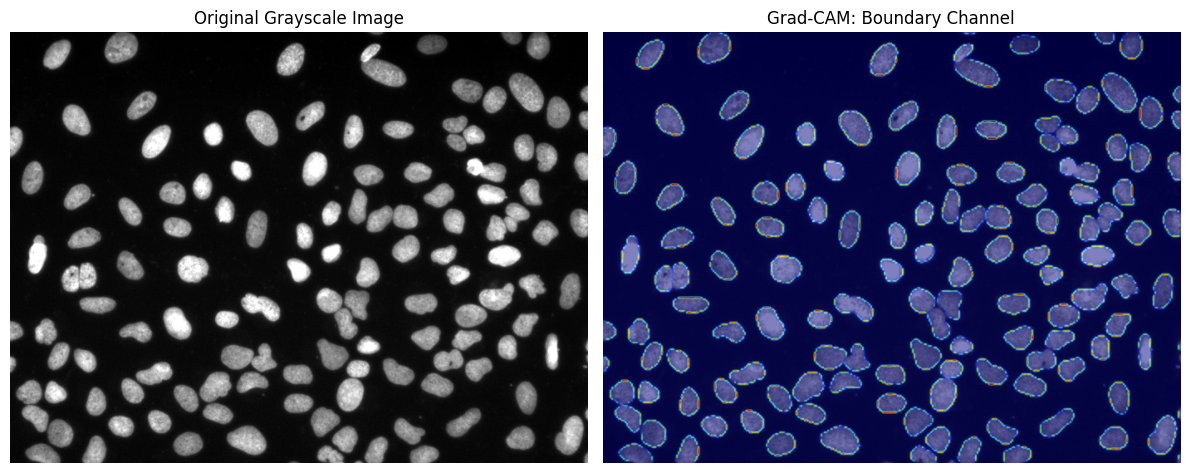

In [38]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

def Segmentation_Grad_CAM(model, image_tensor):
    # 1. Containers to catch the data
    gradients = []
    activations = []

    # 2. Define the Hooks (the "cameras" inside the network)
    def backward_hook(module, grad_input, grad_output):
        gradients.append(grad_output[0].detach())

    def forward_hook(module, input, output):
        activations.append(output.detach())

    # 3. Attach hooks to the final decoder block to see sharp spatial boundaries
    target_layer = model.decoder.decoder4
    forward_handle = target_layer.register_forward_hook(forward_hook)
    backward_handle = target_layer.register_full_backward_hook(backward_hook)

    # 4. Prepare model and image
    model.eval()
    model.zero_grad()
    device = next(model.parameters()).device
    image_tensor = image_tensor.to(device)
    if image_tensor.dim() == 3:            # Accept both (1,H,W) and (1,1,H,W) inputs
        image_tensor = image_tensor.unsqueeze(0)
    image_tensor.requires_grad = True # Forces PyTorch to track gradients all the way back to the image

    # 5. Forward Pass
    pred = model(image_tensor)

    # 6. Isolate the Boundary channel (Index 1) and sum it
    boundary_sum = pred[0, 1, :, :].sum()

    # 7. Flow the gradients backward!
    boundary_sum.backward()

    # 8. Clean up hooks so they don't cause memory leaks
    forward_handle.remove()
    backward_handle.remove()

    # --- HEATMAP MATH ---

    # Global Average Pooling of the gradients
    pooled_gradients = torch.mean(gradients[0], dim=[0, 2, 3])

    # Multiply the activations (feature maps) by the gradient weights
    activation = activations[0].squeeze(0)
    for i in range(activation.size(0)):
        activation[i, :, :] *= pooled_gradients[i]

    # Sum the channels, apply ReLU (discard negative values), and normalize 0 to 1
    heatmap = torch.mean(activation, dim=0).squeeze()
    heatmap = F.relu(heatmap)
    heatmap /= (torch.max(heatmap) + 1e-8)  # epsilon guards against division by zero

    # Resize the heatmap back to the ORIGINAL image size using PyTorch interpolation
    raw_img = image_tensor.squeeze().cpu().detach().numpy()
    H, W = raw_img.shape
    heatmap_resized = F.interpolate(
        heatmap.unsqueeze(0).unsqueeze(0),
        size=(H, W),
        mode='bilinear',
        align_corners=False
    ).squeeze().cpu().numpy()

    # --- VISUALIZATION OVERLAY ---

    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.title("Original Grayscale Image")
    plt.imshow(raw_img, cmap='gray')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.title("Grad-CAM: Boundary Channel")
    plt.imshow(raw_img, cmap='gray')
    # Overlay the glowing heatmap using the 'jet' colormap and 50% transparency
    plt.imshow(heatmap_resized, cmap='jet', alpha=0.5)
    plt.axis('off')

    plt.tight_layout()
    plt.show()

# --- Run it on the winning model (wired by the setup cell above) ---
if winning_model is not None:
    Segmentation_Grad_CAM(winning_model, sample_image_tensor)
else:
    print("Skipped: no finished models found in the checkpoint folder.")

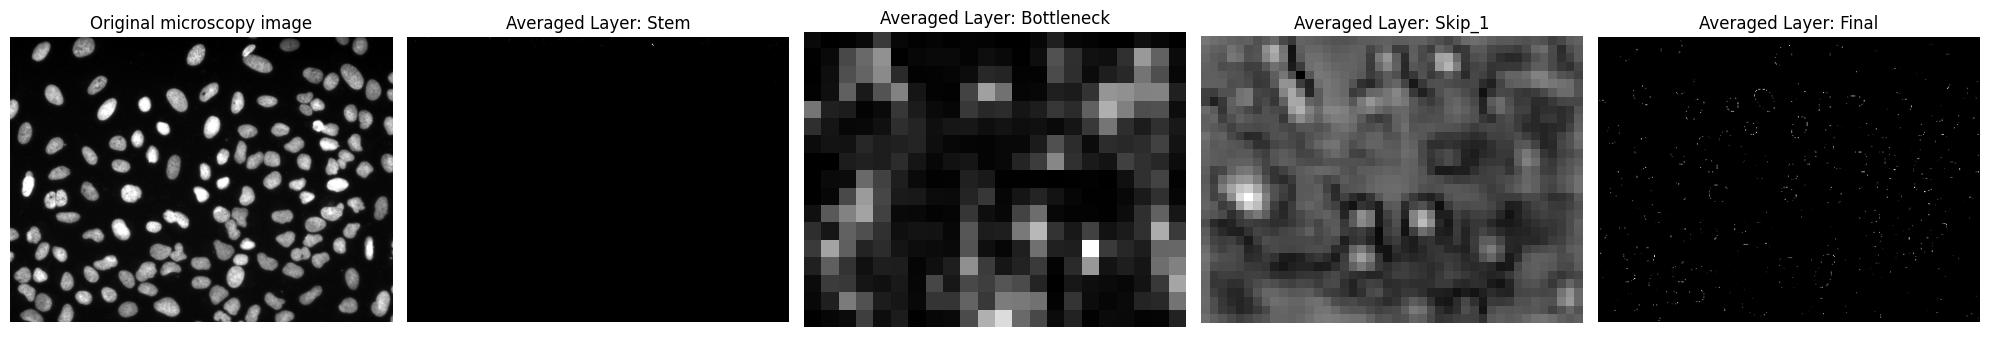

In [39]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

# 1. Container dictionary to act as a database for hidden layers
activations = {}

# 2. Closure hook function that catches the output and detaches it from the computational graph
def get_activation(name):
    def hook(model, input, output):
        activations[name] = output.detach()
    return hook

def Visualize_U_Net_Feature_Maps(model, sample_image_tensor, save_name=""):
    """
    Registers hooks, runs inference, and plots averaged grayscale maps for specified layers.
    """

    # 3. CRITICAL: Initialize container for this specific image run
    activations.clear()

    # 4. Define and Register Hooks before running inference
    # - Stem: Final convolutional layer of the initial block (e.g., after initial downsampling)
    stem_handle = model.encoder.conv1.register_forward_hook(get_activation('stem'))

    # - Bottleneck: The deepest part of the encoder. We assume ResNet backbone from timm
    bottleneck_handle = model.encoder.layer4.register_forward_hook(get_activation('bottleneck'))

    # - Skip Connection 1: Highest resolution skip connection from contracting path to decoder
    #   (We attach to the *decoder* layer that receives the skip, e.g., output of skip manipulation)
    skip_1_handle = model.decoder.decoder1.register_forward_hook(get_activation('skip_1'))

    # - Final Multi-Head output: Before final activation (Softmax)
    final_handle = model.decoder.segmentation_head.register_forward_hook(get_activation('final'))

    # Prepare model and input
    model.eval()
    input_tensor = sample_image_tensor.unsqueeze(0).to(next(model.parameters()).device)

    # 5. Forward Pass (triggers the hooks automatically)
    with torch.no_grad():
        model(input_tensor)

    # 6. Remove hooks to prevent future memory leaks
    stem_handle.remove()
    bottleneck_handle.remove()
    skip_1_handle.remove()
    final_handle.remove()

    # --- Averaging and Plotting Loop ---
    keys = list(activations.keys())

    # Setup Figure (1 row, 5 columns: Original + 4 Feature Maps)
    fig, axes = plt.subplots(1, 1 + len(keys), figsize=(20, 4))

    # Plot Original grayscale image
    raw_img = sample_image_tensor.squeeze().cpu().detach().numpy()
    axes[0].imshow(raw_img, cmap='gray')
    axes[0].set_title("Original microscopy image")
    axes[0].axis('off')

    # Iterate through the hooked layers in activations database
    for idx, key in enumerate(keys):
        # Grab the massively deep tensor (e.g., shape (1, 2048, 16, 16))
        feature_maps = activations[key].squeeze()

        # 7. CRITICAL: Average across the channel dimension (dim=1)
        #    to create a single 2D grayscale image for visualization.
        #    Shape becomes e.g., (16, 16)
        grayscale_map = torch.mean(feature_maps, dim=0).cpu().numpy()

        # Apply ReLU to discard negative activations, and normalize for display
        grayscale_map = np.maximum(grayscale_map, 0)
        grayscale_map /= (np.max(grayscale_map) + 1e-8)  # epsilon guards against division by zero

        # Plot the feature map
        axes[idx + 1].imshow(grayscale_map, cmap='gray')
        axes[idx + 1].set_title(f"Averaged Layer: {key.capitalize()}")
        axes[idx + 1].axis('off')

    # Final visual clean-up and saving
    plt.tight_layout()
    if save_name:
        plt.savefig(f"{save_name}_FeatureMaps.png", dpi=300, bbox_inches='tight')
    plt.show()

# --- Run it on the winning model (wired by the setup cell above) ---
if winning_model is not None:
    Visualize_U_Net_Feature_Maps(winning_model, sample_image_tensor, save_name="winning_model")
else:
    print("Skipped: no finished models found in the checkpoint folder.")


========== Pathological Edge-Case Identification ==========
Scoring progress... Image 0/50...
Scoring completed in 2.11 seconds.

Worst Test Case Performance (Catastrophic Failures):
Dice: 0.0000 | IXMtest_L01_s2_w1E5038251-DBA3-44D0-BC37-E43E2FC8C174.tif
Dice: 0.9240 | IXMtest_A12_s7_w1EAEEA614-51ED-43B3-A4FF-088730911E4C.tif
Dice: 0.9490 | IXMtest_D01_s1_w181AE787C-B5EE-4150-A90E-2FE43165C32E.tif
Dice: 0.9575 | IXMtest_E19_s4_w129545707-4CD3-4498-AC27-E4AE24D0253C.tif
Dice: 0.9602 | IXMtest_J16_s8_w1AD7BC3EB-6A29-4A53-AA59-E39653839B0D.tif
Dice: 0.9608 | IXMtest_G23_s4_w126F855D5-89CE-432B-9592-684B6E5EEF24.tif
Dice: 0.9617 | IXMtest_A22_s8_w1E2AFE190-831D-4D9C-961E-3AA2ECB3599D.tif
Dice: 0.9620 | IXMtest_L06_s5_w1610AE208-D6E8-4DC4-AC19-D26284AA8556.tif
Dice: 0.9626 | IXMtest_E04_s4_w1F5ABC12B-FABD-4E33-AB99-82271209853E.tif
Dice: 0.9628 | IXMtest_O24_s5_w175443699-7C4C-4E5F-9C5F-57A342CC87DE.tif

========== Generating Visual Failure Analysis Grid ==========


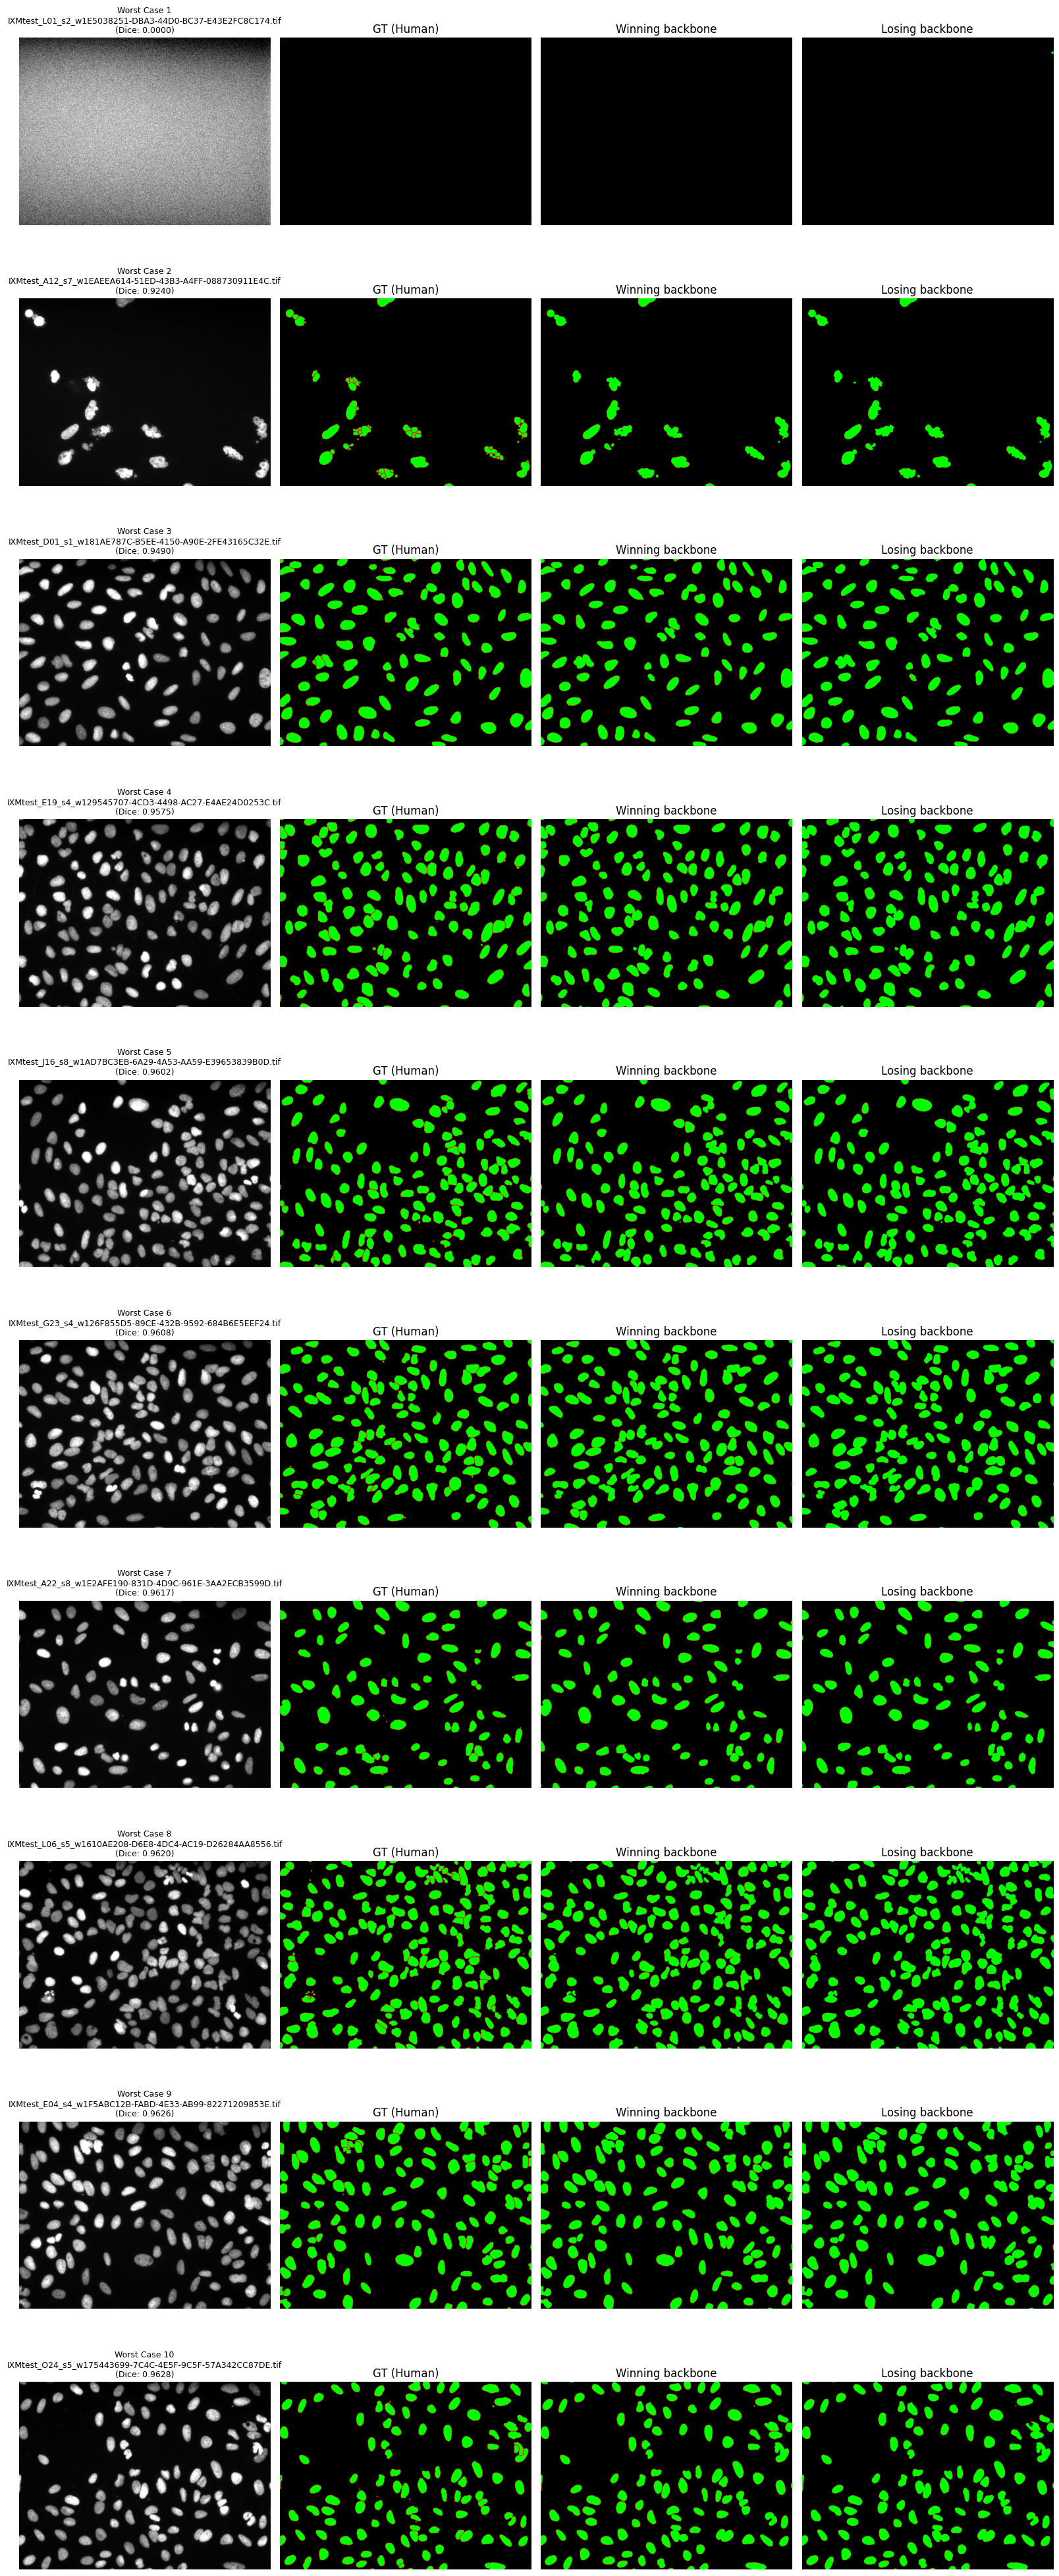

In [40]:
import torch
import matplotlib.pyplot as plt
import numpy as np
import time

def calculate_soft_dice(pred, target, smooth=1e-6):
    '''
    Soft Dice for a single image using the Interior channel (index 2).
    pred/target: (1, 3, H, W) tensors.
    '''
    pred_soft = torch.softmax(pred, dim=1)
    pred_nucleus = pred_soft[0, 2, :, :].cpu()
    target_nucleus = target[0, 2, :, :].cpu()

    intersection = (pred_nucleus * target_nucleus).sum()
    total_sum = pred_nucleus.sum() + target_nucleus.sum()
    dice_score = (2. * intersection + smooth) / (total_sum + smooth)
    return dice_score.item()

def prediction_rgb(pred):
    '''Converts a (1, 3, H, W) logit tensor into an RGB mask: red=boundary, green=interior.'''
    probs = torch.softmax(pred, dim=1).squeeze().cpu().numpy()
    rgb = np.zeros((probs.shape[1], probs.shape[2], 3))
    rgb[..., 0] = probs[1] > 0.5   # Red   = Predicted Boundary
    rgb[..., 1] = probs[2] > 0.5   # Green = Predicted Interior
    return rgb

def Pathological_Case_Sorter_and_Visualizer(winning_model, losing_model, test_dataset, save_name="BBBC039_Pathological_Comparison"):
    '''
    'The Why': finds the test images the WINNING model fails on most (lowest Dice),
    then shows winner vs loser predictions side by side to explain the failure modes.
    '''
    device = next(winning_model.parameters()).device
    winning_model.eval()
    losing_model.eval()

    print("\n========== Pathological Edge-Case Identification ==========")
    image_scores = []
    start_time = time.time()

    # 1. Score EVERY image in the test set one by one (no batch-slicing bugs)
    with torch.no_grad():
        for i in range(len(test_dataset)):
            image, gt = test_dataset[i]
            image_tensor = image.unsqueeze(0).to(device)

            pred = winning_model(image_tensor)
            image_dice = calculate_soft_dice(pred, gt.unsqueeze(0))

            filename = test_dataset.image_paths[i].name  # trace failures back to the raw .tif
            image_scores.append((image_dice, i, filename))

            if i % 50 == 0:
                print(f"Scoring progress... Image {i}/{len(test_dataset)}...", end='\r')

    print(f"\nScoring completed in {time.time() - start_time:.2f} seconds.")

    # 2. Sort from worst (lowest Dice) to best, and isolate the bottom 10
    sorted_scores = sorted(image_scores, key=lambda x: x[0])
    worst_10 = sorted_scores[:10]

    print("\nWorst Test Case Performance (Catastrophic Failures):")
    for score, _, filename in worst_10:
        print(f"Dice: {score:.4f} | {filename}")

    # --- 3. Comparative Visualizer: 10 rows x 4 columns (Original, GT, Winner, Loser) ---
    print("\n========== Generating Visual Failure Analysis Grid ==========")
    fig, axes = plt.subplots(10, 4, figsize=(16, 40))

    for row, (score, idx, filename) in enumerate(worst_10):
        image, gt = test_dataset[idx]
        image_np = image.squeeze().cpu().numpy()
        input_tensor = image.unsqueeze(0).to(device)

        with torch.no_grad():
            winner_pred = winning_model(input_tensor)
            loser_pred  = losing_model(input_tensor)

        # Column 1: Original grayscale image
        axes[row, 0].imshow(image_np, cmap='gray')
        axes[row, 0].set_title(f"Worst Case {row + 1}\n{filename}\n(Dice: {score:.4f})", fontsize=9)
        axes[row, 0].axis('off')

        # Column 2: Ground Truth (red = boundary, green = interior)
        gt_np = gt.numpy()
        gt_rgb = np.zeros((gt_np.shape[1], gt_np.shape[2], 3))
        gt_rgb[..., 0] = gt_np[1] > 0.5
        gt_rgb[..., 1] = gt_np[2] > 0.5
        axes[row, 1].imshow(gt_rgb)
        axes[row, 1].set_title("GT (Human)")
        axes[row, 1].axis('off')

        # Column 3: Winning backbone prediction
        axes[row, 2].imshow(prediction_rgb(winner_pred))
        axes[row, 2].set_title("Winning backbone")
        axes[row, 2].axis('off')

        # Column 4: Losing backbone prediction
        axes[row, 3].imshow(prediction_rgb(loser_pred))
        axes[row, 3].set_title("Losing backbone")
        axes[row, 3].axis('off')

    plt.tight_layout()
    plt.savefig(f"{save_name}.png", dpi=300, bbox_inches='tight')
    plt.show()

# --- Run it (wired by the setup cell above) ---
if losing_model is not None:
    Pathological_Case_Sorter_and_Visualizer(winning_model, losing_model, test_dataset)
elif winning_model is not None:
    print("Skipped: the pathological sorter needs at least 2 finished models (winner + loser).")
else:
    print("Skipped: no finished models found in the checkpoint folder.")
